In [53]:
import ROOT

import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate as interp
import scipy.optimize as opt
import matplotlib as mpl
import scipy.special as sf
import scipy.integrate as integ
import scipy.linalg as la
mpl.rc('xtick', direction='in', top=True)
mpl.rc('ytick', direction='in', right=True)
mpl.rc('xtick.minor', visible=True)
mpl.rc('ytick.minor', visible=True)
import pandas as pd
import glob
import os
import re
import uuid
import json
import inspect




In [54]:
base_path = "first set sent/Results_rootonly"
index_path = os.path.join(base_path, "root_index.json")
with open(index_path, "r") as f:
    index = json.load(f)

In [55]:
hist_info = index['angle88.00']['Pos0.0010000']['histFSfftwPhase_0_0']

filepath = hist_info["filepath"]
file = ROOT.TFile.Open(filepath,'READ')
hist = file.Get('histFSfftwPhase_0_0')

print(hist)

Name: histFSfftwPhase_0_0 Title: Frequency Spectrum: Phase NbinsX: 8192


In [56]:
def process_hist(index, angle, position, hist_name, func,*args, **kwargs):
    hist_info = index[angle][position][hist_name]
    filepath = hist_info["filepath"]
    file = ROOT.TFile.Open(filepath,'READ')
    hist = file.Get(hist_name)

    if not hist:
        print("Missing:", hist_name)
        file.Close()
        return
    clone_name = f"{hist_name}_clone_{uuid.uuid4().hex}"
    hist_copy = hist.Clone(clone_name)
    hist_copy.SetDirectory(0)
    file.Close()

    try:
        sig = inspect.signature(func)
        params = sig.parameters

        optional_metadata = {
            "hist_info": hist_info,
            "angle": angle,
            "position": position,
            "hist_name": hist_name,
        }

        # Check whether func accepts arbitrary keyword arguments like **kwargs
        accepts_any_kwargs = any(
            p.kind == inspect.Parameter.VAR_KEYWORD
            for p in params.values()
        )

        if accepts_any_kwargs:
            extra_kwargs = optional_metadata
        else:
            extra_kwargs = {
                name: value
                for name, value in optional_metadata.items()
                if name in params
            }
    
        # User-provided kwargs should override automatic metadata if there is overlap
        extra_kwargs.update(kwargs)

        result = func(hist_copy, *args, **extra_kwargs)
    finally:
        hist_copy.Delete()
    return result

In [57]:
def print_hist(hist):
    for i in range(1, hist.GetNbinsX() + 1):
        print(hist.GetBinCenter(i), hist.GetBinContent(i))

In [59]:
def plot_hist(hist,angle,position,hist_name, rebin=None, ax=None):
    if rebin is not None and rebin > 1:
        if not isinstance(rebin, int):
            raise ValueError("rebin must be an integer")

        hist.Rebin(rebin)

    nbins = hist.GetNbinsX()

    x = np.empty(nbins)
    y = np.empty(nbins)
    width = np.empty(nbins)

    for i in range(1, nbins + 1):
        x[i - 1] = hist.GetBinCenter(i)
        y[i - 1] = hist.GetBinContent(i)
        width[i - 1] = hist.GetBinWidth(i)


    if ax is None:
        fig, ax = plt.subplots()
    else:
        fig = ax.figure

    ax.bar(x, y, width=width, align="center")

    ax.set_xlabel("Bin center")
    ax.set_ylabel("Counts")
    ax.set_title(f"{angle}, {position}, {hist_name}")

    return fig, ax

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'angle88.00, Pos0.0010000, histPSD_0_0'}, xlabel='Bin center', ylabel='Counts'>)

Warning in <TH1D::Rebin>: ngroup=10 is not an exact divider of nbins=8192.


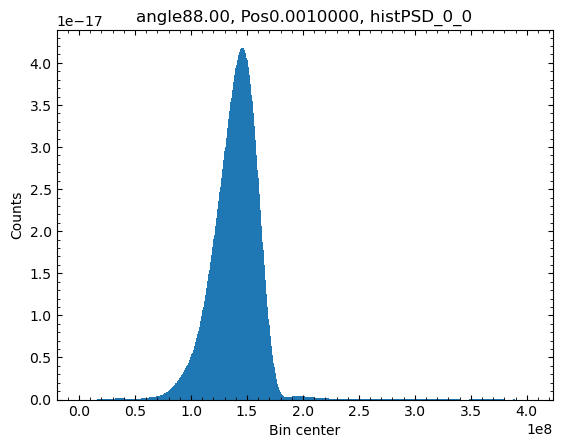

In [63]:
process_hist(index,
                    'angle88.00',
                     'Pos0.0010000',
                     'histPSD_0_0',
                     plot_hist,
                     rebin=10)